In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
import matplotlib.dates as mdates
import matplotlib.patches as mpatches

from plotting_tools import * 

In [3]:
plot_path = f"../plots/case_data"
os.makedirs(plot_path, exist_ok=True)

In [4]:
obs = pd.read_csv(f"../../0_data/cases.csv", sep=",", index_col=False)

obs = obs.fillna(0)
obs = obs.melt(id_vars="Week", value_vars=[c for c in obs.columns if c not in ["Week"]], var_name="Year", value_name="HEV")
obs["Year"] = obs["Year"].astype(int)
obs = pd.concat([obs, pd.DataFrame([{"Week": 53, "Year": 2020, "HEV": 0}])], ignore_index=True)

obs["Category"] = "Non-Emergency"
obs.loc[(obs["Year"] == 2020) & (obs["Week"].between(12, 25)), "Category"] = "Emergency"
obs.loc[(obs["Year"] == 2020) & (obs["Week"] >= 50), "Category"] = "Emergency"
obs.loc[(obs["Year"] == 2021) & (obs["Week"] <= 22), "Category"] = "Emergency"
obs.loc[(obs["Year"] == 2021) & (obs["Week"] >= 45), "Category"] = "Emergency"
obs.loc[(obs["Year"] == 2022) & (obs["Week"] <= 19), "Category"] = "Emergency"

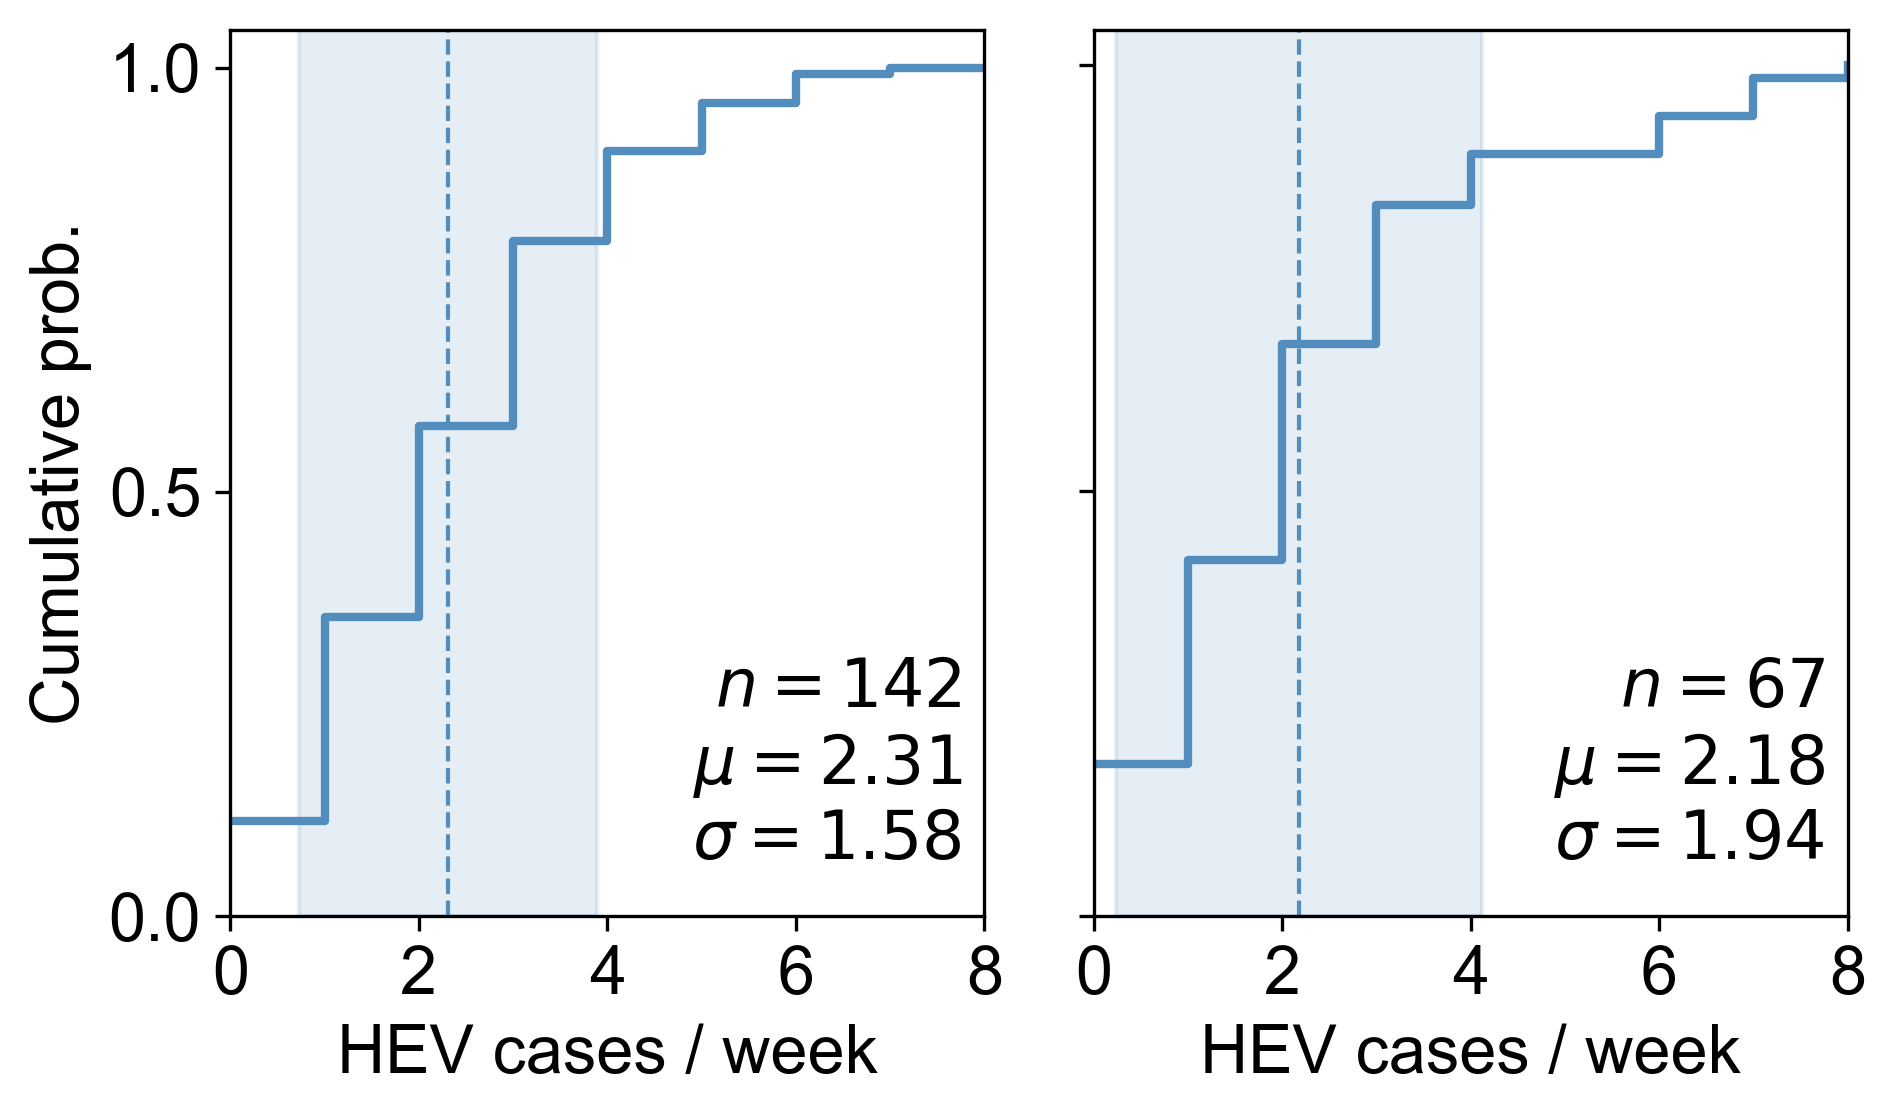

In [5]:
plt.style.use('default')
set_fontsize()

categories = ['Non-Emergency', 'Emergency']
x_min, x_max = obs['HEV'].min(), obs['HEV'].max()
x_grid = np.linspace(x_min, x_max, 200)

fig, axes = plt.subplots(figsize = (6.6,4), nrows=1, ncols=2, dpi=300)

for j, cat in enumerate(categories):
    ax = axes[j]

    subset = obs[(obs['Category'] == cat)].copy()
    vals, counts = np.unique(subset['HEV'].astype(int), return_counts=True)
    cdf = np.cumsum(counts) / counts.sum()
    vals = np.append(vals, x_max)
    cdf = np.append(cdf, 1)
    ax.step(vals, cdf, where = "post", color=lightblue, linewidth=2)
    # ax.plot(subset['HEV'], np.zeros_like(subset['HEV']), marker='|', linestyle='none', markersize=6, alpha=0.4, color = lightblue)

    n = len(subset)
    mean = subset['HEV'].mean()
    sd = subset['HEV'].std(ddof=1)
    ax.axvline(mean, linestyle='--', linewidth = 1, color = lightblue) 
    ax.axvspan(mean - sd, mean + sd, color= lightblue, alpha=0.15)
    text_str = "\n".join([rf"$n = {n}$", rf"$\mu = {mean:.2f}$", rf"$\sigma = {sd:.2f}$"])
    ax.text(0.97, 0.05, text_str, transform=ax.transAxes, ha='right', va='bottom', fontsize=16, bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="none"))

    ax.set_title("")
    ax.set_yticks([0, 0.5, 1])
    ax.set_xticks([0, 2, 4, 6, 8])

    ax.set_xlabel("HEV cases / week")
    ax.ticklabel_format(axis='x', style='plain')
    ax.set_xlim(x_min, x_max)

    if j == 1:
        ax.set_ylabel("")
        ax.set_yticklabels([])
        ax.tick_params(axis='y', which='both', left=True, right=False, labelleft=False)
    else:
        ax.set_ylabel("Cumulative prob.")

# display_names = {'Emergency': 'Lockdown', 'Non-Emergency': 'Non-Lockdown'}
# for j, cat in enumerate(categories):
#     axes[j].set_title(display_names.get(cat, cat))

plt.tight_layout()
plt.savefig(f"{plot_path}/dist-fits.png", dpi=300)
plt.show()

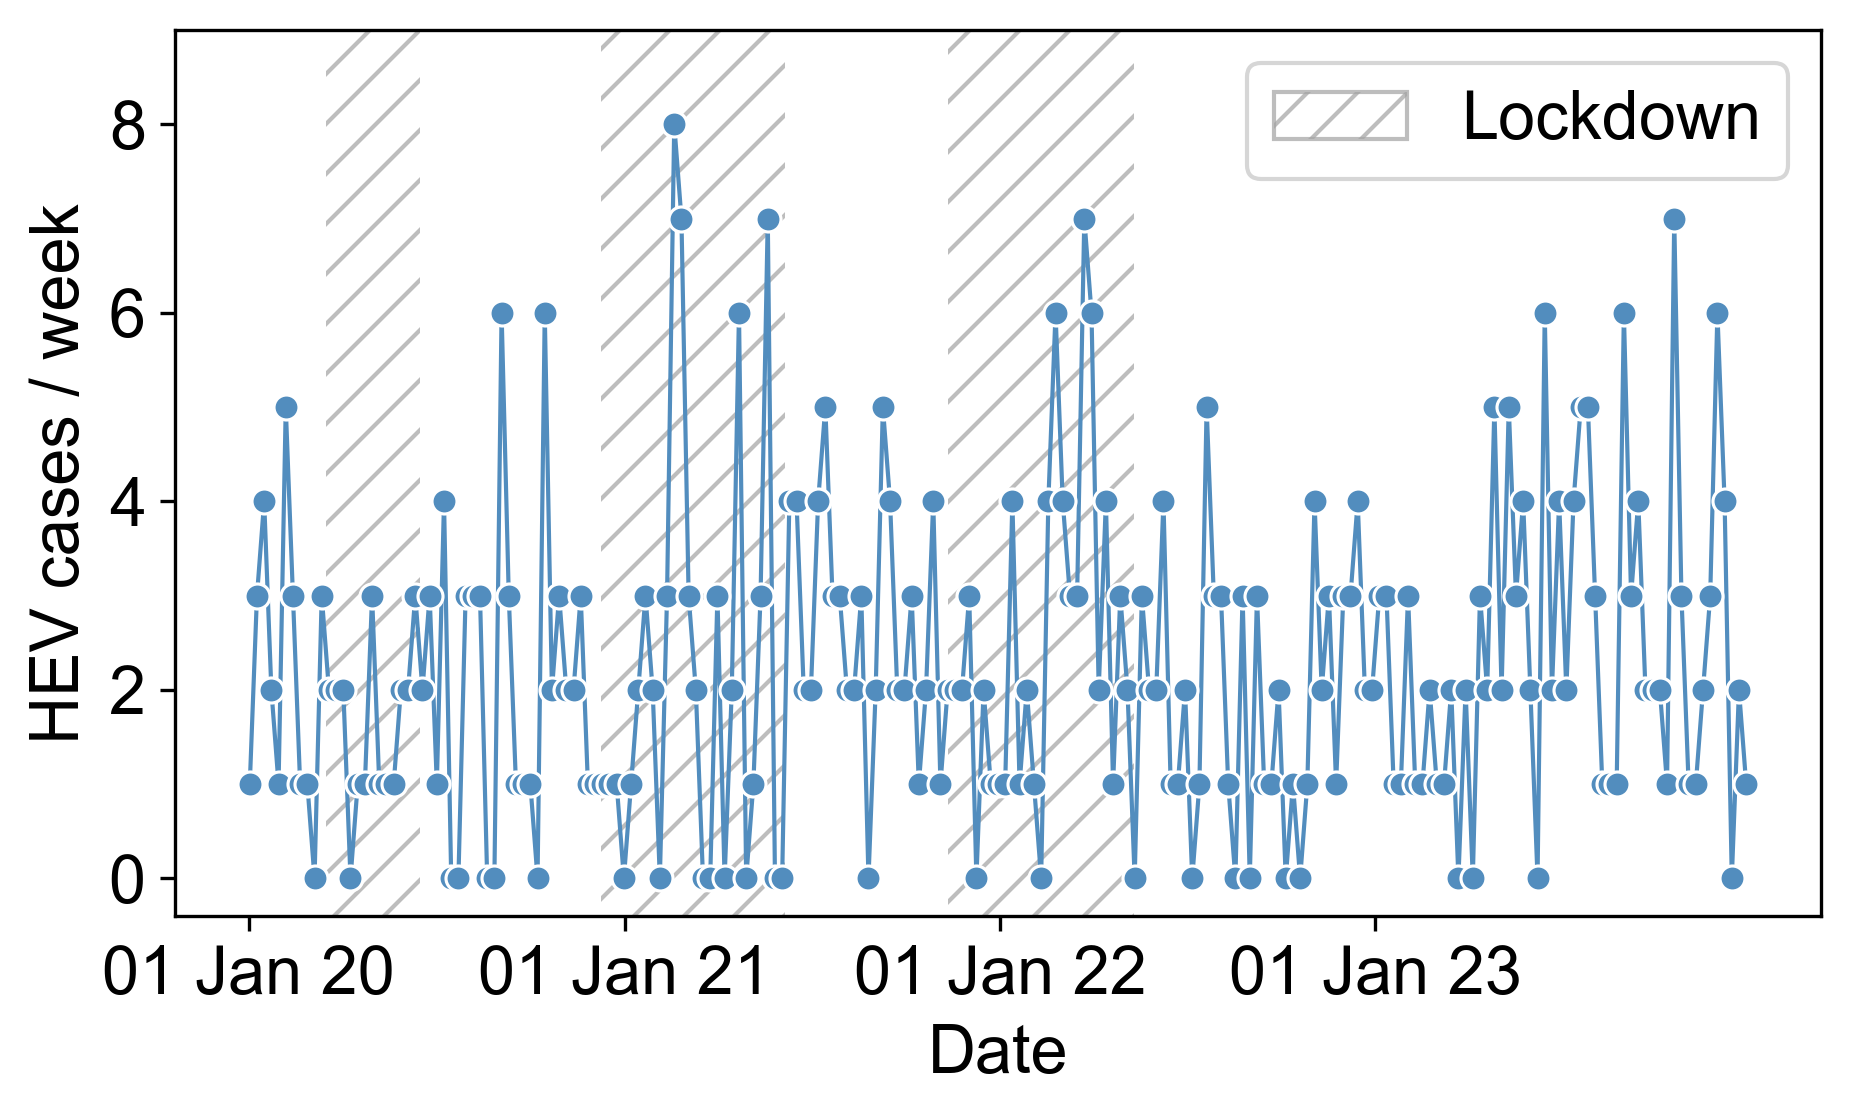

In [6]:
plt.style.use('default')
set_fontsize()

fig, ax = plt.subplots(figsize = (6.45, 4), nrows=1, ncols=1, dpi=300)

obs['Date'] = pd.to_datetime(obs['Year'].astype(str) + obs['Week'].astype(str) + '4', format='%G%V%u')
sns.lineplot(data=obs, x="Date", y="HEV", ax=ax, color = lightblue, linewidth = 1, marker="o", zorder=3)
ax.set_ylabel("HEV cases / week")
ax.set_xticks(pd.to_datetime(["2020-01-01", "2021-01-01", "2022-01-01", "2023-01-01"]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %y"))
ax.set_ylim(None, 9)

lockdown_periods = [
    (pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-16")),
    (pd.Timestamp("2020-12-09"), pd.Timestamp("2021-06-06")),
    (pd.Timestamp("2021-11-11"), pd.Timestamp("2022-05-11"))
]


for start, end in lockdown_periods:
    rect = mpatches.Rectangle((start, 0), width=end - start, height=1, transform=ax.get_xaxis_transform(), facecolor='none', edgecolor=medium_grey,
                              alpha = 0.7, hatch='//', linewidth=0.0, zorder=-10)
    ax.add_patch(rect)

lockdown_patch = mpatches.Patch(facecolor='none', edgecolor=medium_grey, hatch='//', label='Lockdown', alpha=0.7)
ax.legend(handles=[lockdown_patch], loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig(f"{plot_path}/long-fits.png", dpi=300)
plt.show()